# 🚀 Practice Day 52

**📅 Date:** 2026-11-12  
📁 Category: Phase 3 · NumPy+통계 응용 (Round 4/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Apply core statistics (proportions, confidence intervals, z-scores) to compare two email subject line versions
  (비율·신뢰구간·z-score 같은 통계 개념을 두 이메일 제목 버전 비교에 적용해보기)
- Find out whether Version B's higher open rate and faster opens are real, statistically meaningful differences
  (Version B의 높은 개봉률과 빠른 개봉 속도가 실제로 통계적으로 유의미한 차이인지 확인하기)

---
# 📂 Dataset

**Dataset Name:** Subject Line A/B Test — 이메일 마케팅 캠페인 A/B 테스트 결과 / Email Subject Line A/B Test Results

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Results from an email subject-line A/B test sent to 400 recipients (Version A: 200, Version B: 200). Includes whether each email was opened (0/1) and, for opened emails, how many minutes it took to open. Clean — no missing values beyond the expected NaN in time_to_open_min for emails that were never opened, and no duplicates. The focus is on statistically comparing the two versions.
(400명에게 발송한 이메일 제목 A/B 테스트 결과입니다(Version A: 200명, Version B: 200명). 각 이메일의 개봉 여부(0/1)와, 개봉한 경우 개봉까지 걸린 시간(분)을 포함합니다. 개봉하지 않은 이메일의 time_to_open_min이 결측인 것(예상된 결측, 오류 아님) 외에는 결측치·중복이 없습니다. 두 버전을 통계적으로 비교하는 데 초점을 둡니다.)

## Dataset Preview

In [8]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate an email subject-line A/B test: Version A vs Version B ---
n_a, n_b = 200, 200

opened_a = rng.binomial(1, 0.18, n_a)
opened_b = rng.binomial(1, 0.29, n_b)

# time_to_open only applies to opened emails; NaN otherwise
time_a = np.where(opened_a == 1, np.clip(rng.normal(185, 70, n_a), 5, 600), np.nan)
time_b = np.where(opened_b == 1, np.clip(rng.normal(125, 55, n_b), 5, 600), np.nan)

df = pd.DataFrame({
    'recipient_id': [f'R{str(i+1).zfill(4)}' for i in range(n_a + n_b)],
    'version': ['A'] * n_a + ['B'] * n_b,
    'opened': np.concatenate([opened_a, opened_b]),
    'time_to_open_min': np.round(np.concatenate([time_a, time_b]), 1)
})
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,recipient_id,version,opened,time_to_open_min
0,R0062,A,0,NaN
1,R0349,B,0,NaN
2,R0164,A,0,NaN
3,R0008,A,0,NaN
4,R0276,B,0,NaN
5,R0382,B,1,94.4
6,R0209,B,0,NaN
7,R0004,A,0,NaN
8,R0257,B,1,237.9
9,R0168,A,0,NaN


## Dataset Information

In [9]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   recipient_id      400 non-null    str    
 1   version           400 non-null    str    
 2   opened            400 non-null    int64  
 3   time_to_open_min  91 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 12.6 KB

Shape: (400, 4)


,recipient_id,version,opened,time_to_open_min
count,400,400,400.000000,91.000000
unique,400,2,NaN,NaN
top,R0062,A,NaN,NaN
freq,1,200,NaN,NaN
mean,NaN,NaN,0.227500,145.934066
std,NaN,NaN,0.419743,70.109703
min,NaN,NaN,0.000000,22.700000
25%,NaN,NaN,0.000000,92.200000
50%,NaN,NaN,0.000000,139.300000
75%,NaN,NaN,0.000000,200.450000


---
# ❓ Business Questions

1. **(Analysis)** How much higher is Version B's open rate compared to Version A, and does the 95% confidence interval for that difference exclude zero?
   (Version B의 개봉률은 A보다 얼마나 높으며, 그 차이의 95% 신뢰구간은 0을 포함하지 않는가?)
2. **(Analysis)** Among opened emails, how much faster on average did Version B get opened, and is that difference statistically significant (z-score)?
   (개봉된 이메일 기준, Version B는 평균적으로 얼마나 더 빨리 개봉되었으며, 그 차이는 통계적으로 유의한가(z-score)?)
3. **(Analysis)** How does the spread (standard deviation) of time-to-open compare between the two versions?
   (두 버전의 개봉시간 산포(표준편차)는 어떻게 다른가?)
4. **(Visualization)** Compare the open rate between the two versions.
   (두 버전의 개봉률을 비교하면?)
5. **(Visualization)** Compare the distribution of time-to-open between the two versions.
   (두 버전의 개봉시간 분포를 비교하면?)

---
# 🔍 Data Cleaning Check


In [10]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
recipient_id          0
version               0
opened                0
time_to_open_min    309
dtype: int64

Duplicate rows: 0

Dtypes
recipient_id            str
version                 str
opened                int64
time_to_open_min    float64
dtype: object

Column names
['recipient_id', 'version', 'opened', 'time_to_open_min']

Text columns — unique counts
recipient_id    400
version           2
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How much higher is Version B's open rate compared to Version A, and does the 95% confidence interval for that difference exclude zero? (Version B 개봉률은 A보다 얼마나 높은가? 95% 신뢰구간은 0을 포함하지 않는가?)

**Result:** Version B's open rate is **29.50%** and Version A's is **16.00%**, so B is **13.50** percentage points higher. The 95% confidence interval for the difference is **[5.39%, 21.61%]**, which excludes zero.  
(Version B 개봉률은 **29.50%**, Version A는 **16.00%**라서 B가 **13.50**%p 높습니다. 차이의 95% 신뢰구간은 **[5.39%, 21.61%]**이고 0을 포함하지 않습니다)

**Insight:** The lower end is **5.39%**, so B is higher even in the cautious case, and the standard error is **4.14%**.  
(하한이 **5.39%**라서 보수적으로 봐도 B가 높고, 표준오차는 **4.14%**)

In [11]:
# Question 1: open rate by version, 95% CI for the difference in proportions

open_rate_a = np.mean(df[df['version'] == 'A']['opened'])
open_rate_b = np.mean(df[df['version'] == 'B']['opened'])
n_a = len(df[df['version'] == 'A'])
n_b = len(df[df['version'] == 'B'])
se_open = np.sqrt((open_rate_a * (1 - open_rate_a) / n_a) + (open_rate_b * (1 - open_rate_b) / n_b))

open_diff = open_rate_b - open_rate_a
margin = 1.96 * se_open
ci_lower = open_diff - margin
ci_upper = open_diff + margin

print(f"Open rate (Version A): {open_rate_a:.2%}")
print(f"Open rate (Version B): {open_rate_b:.2%}")
print(f"Difference (B - A): {open_diff:.2%}")
print(f"Standard error: {se_open:.2%}")
print(f"95% Confidence interval: [{ci_lower:.2%}, {ci_upper:.2%}]")
print("Excludes zero:", ci_lower > 0 or ci_upper < 0)


Open rate (Version A): 16.00%
Open rate (Version B): 29.50%
Difference (B - A): 13.50%
Standard error: 4.14%
95% Confidence interval: [5.39%, 21.61%]
Excludes zero: True


## Question 2

**Question:** Among opened emails, how much faster on average did Version B get opened, and is that difference statistically significant? (개봉된 이메일 기준, B가 평균 얼마나 빨리 개봉되었는가? 유의한가?)

**Result:** Version B is opened after **124.12** minutes on average and Version A after **186.16**, so B is **62.04** minutes faster. The z-score is **-4.48**.  
(Version B는 평균 **124.12**분, Version A는 **186.16**분 뒤에 열려서 B가 **62.04**분 빠릅니다. z-score는 **-4.48**)

**Insight:** The absolute z-score is above **1.96**, so the difference is significant at the 5% level. The standard error is **13.86** minutes, because only opened emails are counted.  
(z-score의 절댓값이 **1.96**보다 커서 5% 수준에서 유의합니다. 개봉된 이메일만 세기 때문에 표준오차는 **13.86**분)

In [15]:
# Question 2: mean time_to_open (opened emails only) by version, standard error, z-score

mean_time_a = np.mean(df[df['version'] == 'A']['time_to_open_min'])
mean_time_b = np.mean(df[df['version'] == 'B']['time_to_open_min'])
std_time_a = np.std(df[df['version'] == 'A']['time_to_open_min'])
std_time_b = np.std(df[df['version'] == 'B']['time_to_open_min'])
n_a = len(df[(df['version'] == 'A') & (df['opened'] == 1)])
n_b = len(df[(df['version'] == 'B') & (df['opened'] == 1)])
se_time = np.sqrt((std_time_a**2 / n_a) + (std_time_b**2 / n_b))
z_score = (mean_time_b - mean_time_a) / se_time

print(f"Mean time to open (Version A): {mean_time_a:.2f} minutes")
print(f"Mean time to open (Version B): {mean_time_b:.2f} minutes")
print(f"Standard deviation (Version A): {std_time_a:.2f} minutes")
print(f"Standard deviation (Version B): {std_time_b:.2f} minutes")
print(f"Standard error: {se_time:.2f} minutes")
print(f"Z-score: {z_score:.2f}")

Mean time to open (Version A): 186.16 minutes
Mean time to open (Version B): 124.12 minutes
Standard deviation (Version A): 63.16 minutes
Standard deviation (Version B): 63.10 minutes
Standard error: 13.86 minutes
Z-score: -4.48


## Question 3

**Question:** How does the spread (standard deviation) of time-to-open compare between the two versions? (두 버전의 개봉시간 산포는 어떻게 다른가?)

**Result:** The standard deviation of time-to-open is **63.16** minutes for Version A and **63.10** minutes for Version B, a gap of **0.06**.  
(개봉시간 표준편차는 Version A **63.16**분, Version B **63.10**분으로 **0.06** 차이입니다)

**Insight:** The two spreads are almost the same, so the difference between versions is in the mean, not the spread.  
(두 산포가 거의 같아서 버전 간 차이는 산포가 아니라 평균에 있습니다)

In [13]:
# Question 3: standard deviation of time_to_open by version (opened emails only)

std_time_a = np.std(df[df['version'] == 'A']['time_to_open_min'])
std_time_b = np.std(df[df['version'] == 'B']['time_to_open_min'])
print(f"Standard deviation (Version A): {std_time_a:.2f} minutes")
print(f"Standard deviation (Version B): {std_time_b:.2f} minutes")

Standard deviation (Version A): 63.16 minutes
Standard deviation (Version B): 63.10 minutes


---
# 📈 Visualization

**Chart 1:** Bar chart — open rate by version (막대그래프: 버전별 개봉률)

*Interpretation:* Version B's bar is **29.5%** and Version A's is **16.0%**, the **13.5** point gap from Question 1.  
(Version B 막대는 **29.5%**, Version A는 **16.0%**로, Q1의 **13.5**%p 차이와 같습니다)

---

**Chart 2:** Box plot (or histogram) — time-to-open distribution by version (박스플롯 또는 히스토그램: 버전별 개봉시간 분포)

*Interpretation:* Version B's median is about **124** minutes against about **195** for Version A, and the boxes have a similar width, matching the equal standard deviations (**63.10** vs **63.16**).  
(Version B 중앙값은 약 **124**분, Version A는 약 **195**분이고 박스 폭은 비슷해서 거의 같은 표준편차(**63.10** 대 **63.16**)와 맞습니다)

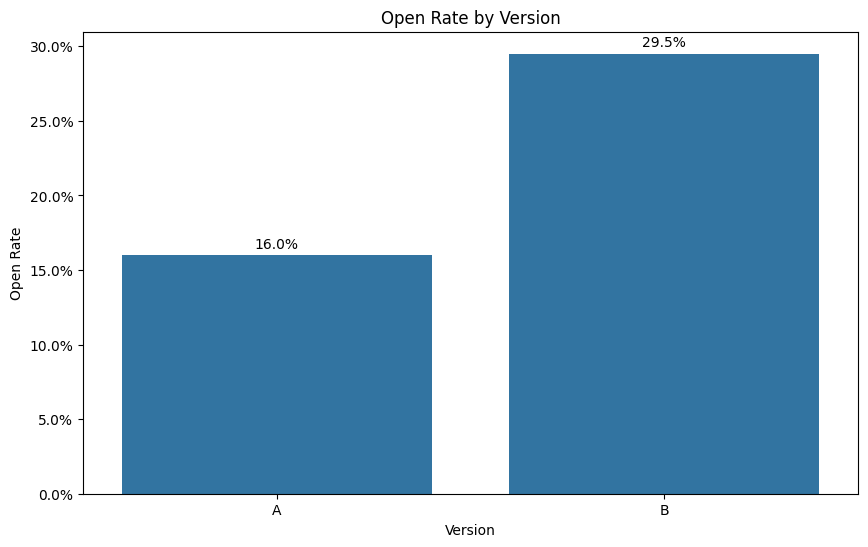

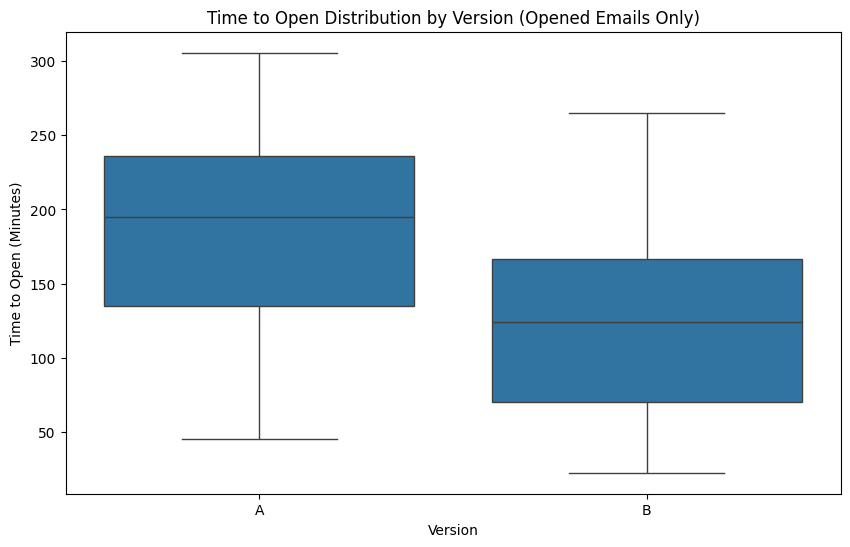

In [14]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Chart 1: open rate by version (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='version', y='opened', data=df, order=['A', 'B'], errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:.1%}' for v in container.datavalues], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Open Rate by Version')
ax.set_xlabel('Version')
ax.set_ylabel('Open Rate')
plt.show()

# Chart 2: time to open distribution by version, opened emails only (box plot or histogram)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='version', y='time_to_open_min', data=df[df['opened'] == 1], order=['A', 'B'], ax=ax)
ax.set_title('Time to Open Distribution by Version (Opened Emails Only)')
ax.set_xlabel('Version')
ax.set_ylabel('Time to Open (Minutes)')
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Version B's open rate is **13.50** points higher (**29.50%** vs **16.00%**), and the 95% interval **[5.39%, 21.61%]** excludes zero.  
  (Version B 개봉률이 **13.50**%p 높고(**29.50%** 대 **16.00%**), 95% 신뢰구간 **[5.39%, 21.61%]**은 0을 포함하지 않음)
- Opened Version B emails are opened **62.04** minutes faster (**124.12** vs **186.16**), with a z-score of **-4.48**.  
  (개봉된 Version B 이메일이 **62.04**분 더 빨리 열림(**124.12**분 대 **186.16**분), z-score **-4.48**)
- The spread of opening time is the same for both versions (**63.10** vs **63.16** minutes).  
  (개봉시간 산포는 두 버전이 같음(**63.10**분 대 **63.16**분))  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Prefer Version B's subject line, since its open rate interval is above zero (**5.39%** to **21.61%** higher) and it is opened **62.04** minutes faster.  
   (개봉률 구간이 0보다 위(**5.39%**~**21.61%**p 높음)이고 **62.04**분 더 빨리 열리므로 Version B 제목을 선호)
2. Report the open-rate gap as **13.50** points with its interval, not as one number.  
   (개봉률 차이는 숫자 하나가 아니라 **13.50**%p와 구간으로 보고)
3. Compare time-to-open only among opened emails, as the chart does.  
   (개봉시간은 차트처럼 개봉된 이메일끼리만 비교)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- In Question 2, `n_a` and `n_b` counted all **200** recipients instead of only the opened emails, so the standard error was too small (**6.31**) and the z-score too large (**-9.83**).  
  (Q2에서 `n_a`, `n_b`가 개봉된 이메일이 아니라 수신자 **200**명 전체를 세어서, 표준오차가 너무 작고(**6.31**) z-score가 너무 컸음(**-9.83**))  

---
# ✅ What I Learned
*Today's biggest lesson*

- The 95% interval for a difference of proportions is (B − A) ± 1.96 × SE, and zero outside it means a significant gap.  
  (비율 차이의 95% 구간은 (B − A) ± 1.96 × SE이고, 0이 밖에 있으면 유의한 차이)
- `time_to_open_min` is NaN for unopened emails, so the mean and standard deviation use opened emails only, and `n` must count only opened emails too.  
  (개봉하지 않은 이메일은 `time_to_open_min`이 NaN이라 평균과 표준편차는 개봉된 이메일만 쓰고, `n`도 개봉된 이메일만 세야 함)  

---
# 🧠 Reflection

**What was difficult?**  
Choosing the right `n` for the standard error in Question 2.  
(Q2에서 표준오차에 쓸 올바른 `n` 고르기)

**Why?**  
The mean and standard deviation skip NaN automatically, but `len()` of a group still counts every recipient.  
(평균과 표준편차는 NaN을 자동으로 건너뛰지만, 그룹의 `len()`은 수신자 전체를 셈)

**How did I solve it?**  
I counted rows with `opened == 1` in each version, which changed the standard error from **6.31** to **13.86**.  
(각 버전에서 `opened == 1`인 행을 세어 표준오차가 **6.31**에서 **13.86**으로 바뀜)

**What would I do differently next time?**  
Check that `n` counts the same rows as the mean and standard deviation.  
(`n`이 평균과 표준편차에 쓴 행과 같은 행을 세는지 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The interval and the z-scores now match the questions. Version B is opened **62.04** minutes faster, with a z-score of **-4.48**.  
(신뢰구간과 z-score가 이제 질문과 맞음. Version B가 **62.04**분 더 빨리 열리고 z-score는 **-4.48**)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
Picking the right `n` for the standard error took the most work.  
(표준오차에 쓸 `n`을 고르는 데 손이 가장 많이 갔음)  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 64 — Numpy stats  
  (NumPy로 통계 응용하기)  